# 02 – Checks of the 10 m DEM and of the study glaciers

Checks of `data/processed/dem_10m.tif` (produced by `src/prepare_dem.py`) and of `data/processed/sgi2023_zone.gpkg` (produced by `src/prepare_sgi.py`):

1. overview: extent, coverage, selected glaciers;
2. seams between tiles: no step every kilometre;
3. comparison with the original 2 m DEM at Alphubel;
4. elevations of summits and of the glenglat boreholes.

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.patches import Rectangle
from pyproj import Transformer
from rasterio.windows import from_bounds

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from config import DEM_RES, EXTENT, PROCESSED, RAW
from relief import hillshade

BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#1a1a1a"
FIG = ROOT / "figures"

In [2]:
with rasterio.open(PROCESSED / f"dem_{DEM_RES}m.tif") as src:
    dem, transform, crs = src.read(1), src.transform, src.crs
glaciers = gpd.read_file(PROCESSED / "sgi2023_zone.gpkg")
shade = hillshade(dem, DEM_RES)
xmin, ymin, xmax, ymax = EXTENT
img_extent = (xmin, xmax, ymin, ymax)  # order expected by imshow

print("CRS:", crs, "| pixel:", DEM_RES, "m | size:", dem.shape[1], "x", dem.shape[0])
print(f"Coverage: {np.isfinite(dem).mean():.1%} | elevations: {np.nanmin(dem):.0f}–{np.nanmax(dem):.0f} m")
print("Selected glaciers:", len(glaciers), f"({glaciers['area_km2'].sum():.1f} km²)")

CRS: EPSG:2056 | pixel: 10 m | size: 3400 x 2300
Coverage: 97.1% | elevations: 1121–4543 m
Selected glaciers: 127 (158.6 km²)


## 1. Overview

Expected: a full rectangle (except two small corners in the south, outside Switzerland), and no selected glacier cut by the boundary. The lettered frames are the zooms of section 2.

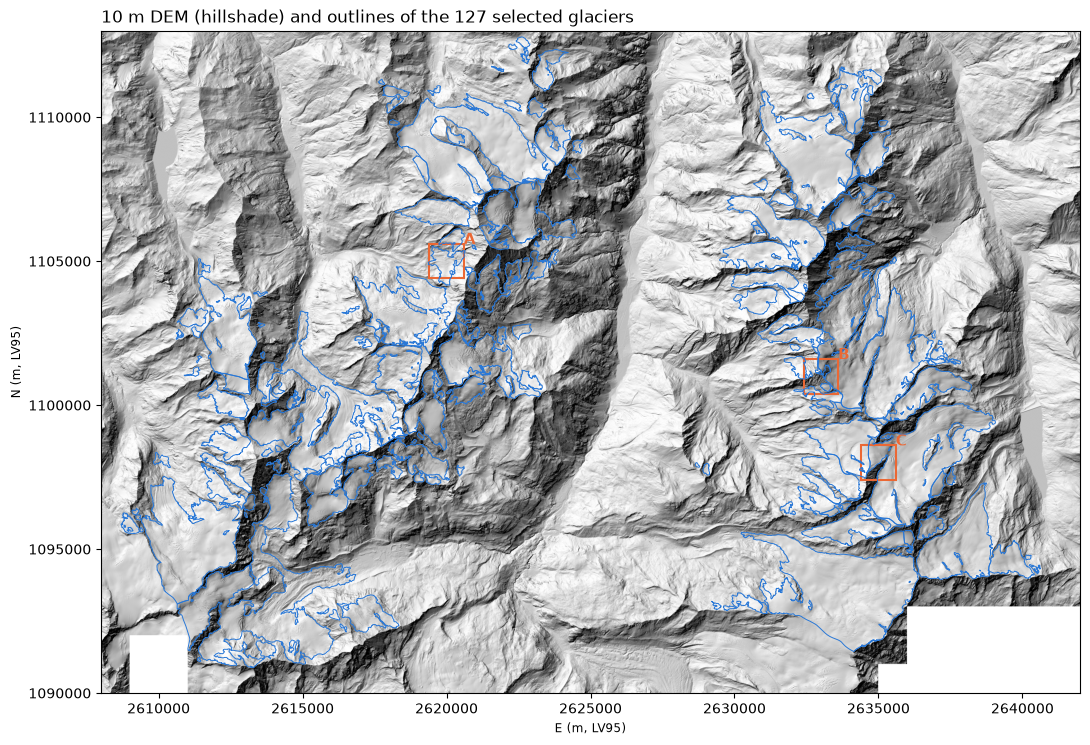

In [3]:
# Three tile corners (round kilometres) in steep terrain, for section 2
corners = {"A": (2_620_000, 1_105_000), "B": (2_633_000, 1_101_000), "C": (2_635_000, 1_098_000)}
HALF = 600  # half-width of the zooms (m)

fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(shade, cmap="gray", extent=img_extent, vmin=-0.2, vmax=1)
glaciers.boundary.plot(ax=ax, color=BLUE, linewidth=0.7)
for name, (x, y) in corners.items():
    ax.add_patch(Rectangle((x - HALF, y - HALF), 2 * HALF, 2 * HALF, fill=False, color=ORANGE, linewidth=1.5))
    ax.annotate(name, (x + HALF, y + HALF), color=ORANGE, fontweight="bold", fontsize=11)
ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
ax.ticklabel_format(style="plain")
ax.set_xlabel("E (m, LV95)"); ax.set_ylabel("N (m, LV95)")
ax.set_title(f"10 m DEM (hillshade) and outlines of the {len(glaciers)} selected glaciers", loc="left")
fig.tight_layout()
fig.savefig(FIG / "02_check_overview.png", dpi=200)
plt.show()

## 2. Seams between tiles

Tiles are 1 km wide, i.e. 100 pixels at 10 m. A merging error would create a step at every round kilometre. Quantitative test: the mean elevation difference between neighbouring pixels, as a function of the position within the tile (0 to 99). With seams, the value jumps at position 0 (crossing from one tile to the next); without seams the curve is flat.

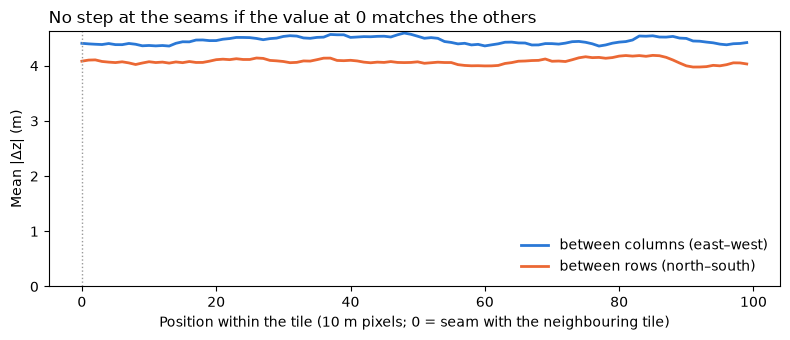

east–west: at the seam 4.41 m, elsewhere 4.45 ± 0.06 m
north–south: at the seam 4.08 m, elsewhere 4.08 ± 0.05 m


In [4]:
def difference_by_position(z, axis):
    """Mean |Δz| between neighbouring pixels, by position within the tile (0 = tile edge)."""
    dz = np.abs(np.diff(z, axis=axis))  # dz[i] = difference between pixels i and i+1
    mean = np.nanmean(dz, axis=1 - axis)
    position = (np.arange(mean.size) + 1) % 100  # position of pixel i+1 within its tile
    return pd.Series(mean).groupby(position).mean()

east_west = difference_by_position(dem, axis=1)
north_south = difference_by_position(dem, axis=0)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(east_west.index, east_west.values, color=BLUE, linewidth=2, label="between columns (east–west)")
ax.plot(north_south.index, north_south.values, color=ORANGE, linewidth=2, label="between rows (north–south)")
ax.axvline(0, color="#999999", linestyle=":", linewidth=1)
ax.set_xlabel("Position within the tile (10 m pixels; 0 = seam with the neighbouring tile)")
ax.set_ylabel("Mean |Δz| (m)")
ax.set_ylim(0, None)
ax.legend(frameon=False)
ax.set_title("No step at the seams if the value at 0 matches the others", loc="left")
fig.tight_layout()
fig.savefig(FIG / "02_check_seams_profile.png", dpi=200)
plt.show()

for name, s in [("east–west", east_west), ("north–south", north_south)]:
    print(f"{name}: at the seam {s[0]:.2f} m, elsewhere {s.drop(0).mean():.2f} ± {s.drop(0).std():.2f} m")

Visual check of the three corners: the dashed lines mark the tile edges. No straight line should appear in the hillshade along them.

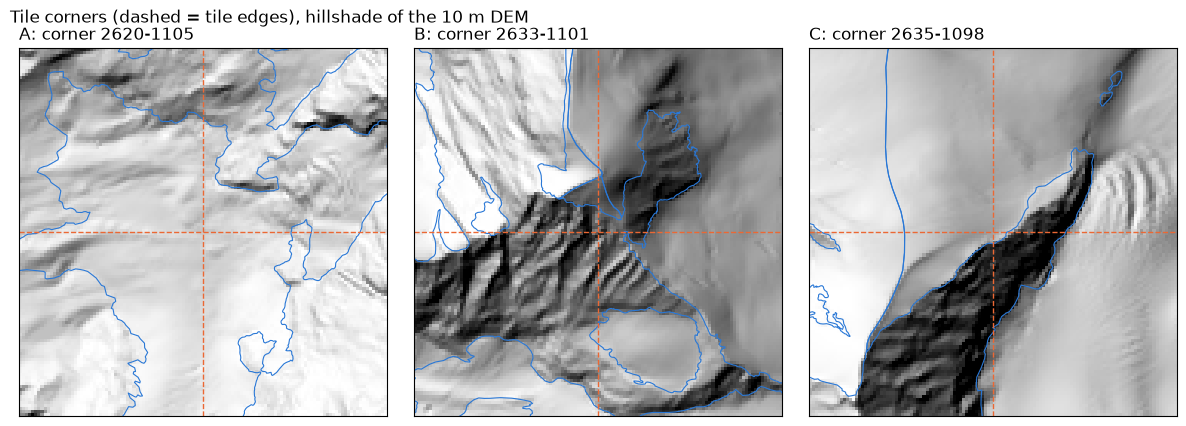

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, (name, (x, y)) in zip(axes, corners.items()):
    rows, cols = from_bounds(x - HALF, y - HALF, x + HALF, y + HALF, transform).toslices()
    ax.imshow(shade[rows, cols], cmap="gray", vmin=-0.2, vmax=1,
              extent=(x - HALF, x + HALF, y - HALF, y + HALF))
    glaciers.boundary.plot(ax=ax, color=BLUE, linewidth=0.8)
    ax.axvline(x, color=ORANGE, linestyle="--", linewidth=1)
    ax.axhline(y, color=ORANGE, linestyle="--", linewidth=1)
    ax.set_xlim(x - HALF, x + HALF); ax.set_ylim(y - HALF, y + HALF)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_title(f"{name}: corner {x // 1000}-{y // 1000}", loc="left")
fig.suptitle("Tile corners (dashed = tile edges), hillshade of the 10 m DEM", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG / "02_check_seams_zooms.png", dpi=200)
plt.show()

## 3. Comparison with the original 2 m DEM (Alphubel)

The 10 m DEM must be a smoothed version of the 2 m one, with no shift. We compare the hillshade of both on the tile containing the Alphubel boreholes, and check that each 10 m pixel is exactly the mean of the corresponding 5 × 5 pixels at 2 m.

In [6]:
# glenglat boreholes (Alphubel and Chessjengletscher), converted to LV95
boreholes = pd.read_csv(RAW / "glenglat/data/borehole.csv")
boreholes = boreholes[boreholes["glacier_name"].isin(["Alphubel South", "Chessjengletscher"])]
to_lv95 = Transformer.from_crs(4326, 2056, always_xy=True)
boreholes["x"], boreholes["y"] = to_lv95.transform(boreholes["longitude"].values, boreholes["latitude"].values)

alphubel = boreholes[boreholes["glacier_name"] == "Alphubel South"]
tile_x, tile_y = int(alphubel["x"].mean() // 1000), int(alphubel["y"].mean() // 1000)
file_2m = next((RAW / "swissalti3d").glob(f"*_{tile_x}-{tile_y}_2_*.tif"))
with rasterio.open(file_2m) as src:
    dem_2m, b = src.read(1), src.bounds
rows, cols = from_bounds(*b, transform).toslices()
dem_10m_tile = dem[rows, cols]

mean_5x5 = dem_2m.reshape(100, 5, 100, 5).mean(axis=(1, 3))
print("Tile:", file_2m.name)
print(f"Max difference between the 10 m DEM and the 5x5 mean of the 2 m DEM: {np.abs(dem_10m_tile - mean_5x5).max():.4f} m")

Tile: swissalti3d_2024_2633-1100_2_2056_5728.tif
Max difference between the 10 m DEM and the 5x5 mean of the 2 m DEM: 0.0000 m


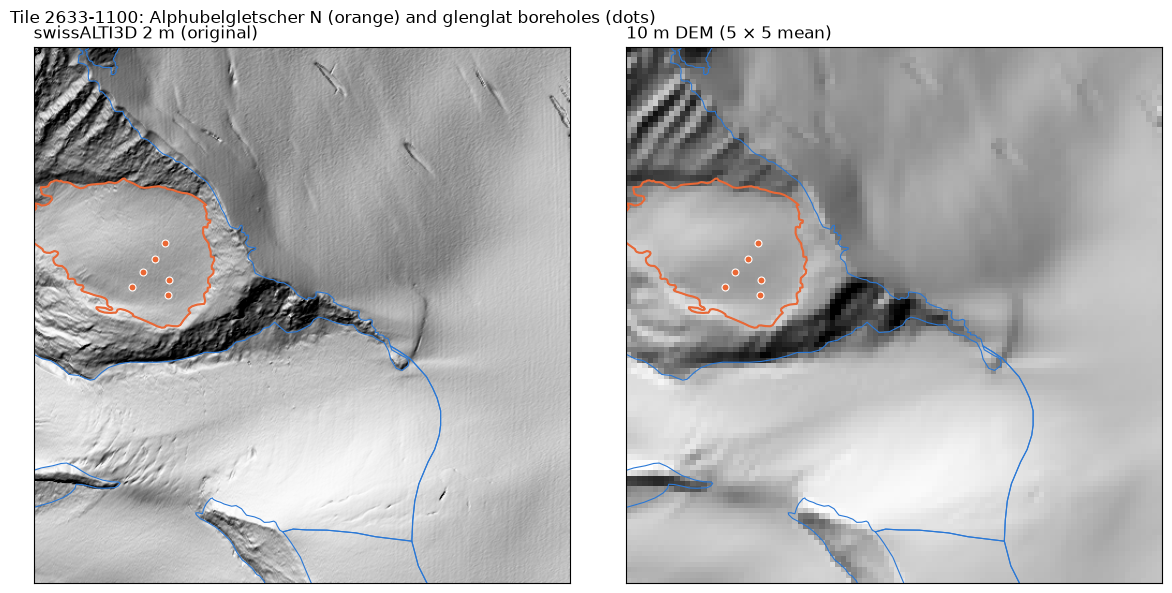

In [7]:
alphubel_outline = glaciers[glaciers["sgi-id"] == "B55-15"]
tile_extent = (b.left, b.right, b.bottom, b.top)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, z, res, title in [(axes[0], dem_2m, 2, "swissALTI3D 2 m (original)"),
                         (axes[1], dem_10m_tile, 10, "10 m DEM (5 × 5 mean)")]:
    ax.imshow(hillshade(z, res), cmap="gray", vmin=-0.2, vmax=1, extent=tile_extent)
    glaciers.boundary.plot(ax=ax, color=BLUE, linewidth=0.8)
    alphubel_outline.boundary.plot(ax=ax, color=ORANGE, linewidth=1.5)
    ax.scatter(alphubel["x"], alphubel["y"], s=25, color=ORANGE, edgecolor="white", linewidth=0.8, zorder=3)
    ax.set_xlim(b.left, b.right); ax.set_ylim(b.bottom, b.top)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_title(title, loc="left")
fig.suptitle(f"Tile {tile_x}-{tile_y}: Alphubelgletscher N (orange) and glenglat boreholes (dots)",
             x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG / "02_check_alphubel_2m_10m.png", dpi=200)
plt.show()

## 4. Elevations: summits and boreholes

**Summits.** We take the highest DEM point within 300 m of the approximate position of each summit, at 2 m and at 10 m. The 10 m value should be slightly lower than the 2 m one (a mean over 100 m² flattens the summit); the 2 m value should be close to the official elevation.

Official elevations (swisstopo maps) and approximate positions: to be confirmed by the user.

In [8]:
summits = pd.DataFrame([
    # name, lon, lat (approximate), official elevation (m)
    ("Dom", 7.8592, 46.0940, 4545),
    ("Täschhorn", 7.8569, 46.0839, 4491),
    ("Weisshorn", 7.7163, 46.1014, 4506),
    ("Alphubel", 7.8638, 46.0630, 4206),
    ("Allalinhorn", 7.8950, 46.0464, 4027),
    ("Zinalrothorn", 7.6903, 46.0647, 4221),
], columns=["summit", "lon", "lat", "official"])
summits["x"], summits["y"] = to_lv95.transform(summits["lon"].values, summits["lat"].values)


def local_max_2m(x, y, radius=300):
    """Highest point of the 2 m tiles within a ±radius square around (x, y)."""
    top = -np.inf
    for f in (RAW / "swissalti3d").glob("*_2_*.tif"):
        tx, ty = (int(v) * 1000 for v in f.name.split("_")[2].split("-"))
        if tx + 1000 < x - radius or tx > x + radius or ty + 1000 < y - radius or ty > y + radius:
            continue  # tile too far away
        with rasterio.open(f) as src:
            window = from_bounds(x - radius, y - radius, x + radius, y + radius, src.transform)
            z = src.read(1, window=window, boundless=True, fill_value=-9999)
        top = max(top, z.max())
    return top


def local_max_10m(x, y, radius=300):
    rows, cols = from_bounds(x - radius, y - radius, x + radius, y + radius, transform).toslices()
    return np.nanmax(dem[rows, cols])


summits["dem_2m"] = [local_max_2m(x, y) for x, y in zip(summits["x"], summits["y"])]
summits["dem_10m"] = [local_max_10m(x, y) for x, y in zip(summits["x"], summits["y"])]
summits["2m - official"] = summits["dem_2m"] - summits["official"]
summits["10m - 2m"] = summits["dem_10m"] - summits["dem_2m"]
summits[["summit", "official", "dem_2m", "dem_10m", "2m - official", "10m - 2m"]].round(1)

,summit,official,dem_2m,dem_10m,2m - official,10m - 2m
0,Dom,4545,4545.000000,4542.600098,-0.0,-2.4
1,Täschhorn,4491,4491.299805,4488.700195,0.3,-2.5
2,Weisshorn,4506,4504.799805,4501.899902,-1.2,-2.9
3,Alphubel,4206,4202.600098,4201.299805,-3.4,-1.2
4,Allalinhorn,4027,4027.600098,4024.000000,0.6,-3.6
5,Zinalrothorn,4221,4221.600098,4215.000000,0.6,-6.5


**Boreholes.** The elevations supplied with the glenglat boreholes (measured in the field in 2024–2025) are compared with the DEM at the same point. The DEM dates from 2024: a few metres of difference are expected (surface melt, snow, GNSS accuracy of the boreholes, 10 m smoothing).

In [9]:
def elevation_at(z, tr, x, y):
    row, col = rasterio.transform.rowcol(tr, x, y)
    return z[row, col]


boreholes["dem_10m"] = [elevation_at(dem, transform, x, y) for x, y in zip(boreholes["x"], boreholes["y"])]
boreholes["dem - borehole"] = boreholes["dem_10m"] - boreholes["elevation"]
print(f"10 m DEM - borehole elevation: mean {boreholes['dem - borehole'].mean():+.1f} m, "
      f"max {boreholes['dem - borehole'].abs().max():.1f} m")
boreholes[["glacier_name", "label", "date_min", "elevation", "dem_10m", "dem - borehole"]].round(1)

10 m DEM - borehole elevation: mean +0.1 m, max 2.9 m


,glacier_name,label,date_min,elevation,dem_10m,dem - borehole
812,Alphubel South,AH1G,2025-08-05,3802.0,3801.300049,-0.7
813,Alphubel South,AH2G,2025-08-06,3759.0,3761.899902,2.9
814,Alphubel South,AH3G,2025-08-06,3820.0,3820.699951,0.7
818,Chessjengletscher,CJ1G,2025-08-07,3031.0,3030.300049,-0.7
819,Chessjengletscher,CJ2G,2025-08-07,3005.0,3003.699951,-1.3
820,Alphubel South,AH1TT,2024-08-21,3775.0,3772.899902,-2.1
821,Alphubel South,AH2TT,2024-08-21,3789.0,3790.699951,1.7
822,Alphubel South,AH3TT,2025-08-06,3781.0,3779.899902,-1.1
823,Chessjengletscher,CJ1TT,2024-08-09,2983.0,2985.600098,2.6
824,Chessjengletscher,CJ2TT,2024-08-09,3027.0,3026.899902,-0.1


## Summary

| Check | Result | Verdict |
|---|---|---|
| Extent and coverage | 3,400 × 2,300 pixels of 10 m, 97.1 % covered; only two corners in the south are empty (no tile), far from any glacier | OK |
| Selected glaciers | 127 whole glaciers, none cut by the boundary, all with an elevation in every pixel | OK |
| Seams between tiles | Difference between neighbouring pixels at the seam identical to the rest of the tile (≈ 4.4 m east–west, ≈ 4.1 m north–south); no line visible on the zooms | OK |
| Fidelity to the 2 m DEM | Each 10 m pixel is exactly the 5 × 5 mean of the 2 m DEM (difference 0.0000 m); same terrain, smoothed | OK |
| Summits | The 2 m DEM matches the official elevations within ±1 m (−3.4 m at Alphubel, a snow dome); the 10 m DEM is 1 to 6.5 m lower, an expected effect of the mean | OK |
| glenglat boreholes | 10 m DEM − elevation of the 12 boreholes: mean +0.1 m, max 2.9 m | OK |

Limitation to keep in mind: at 10 m, ridges and summits are lowered by a few metres and steps narrower than 20–30 m are smoothed out. For a detailed profile of a small glacier (Alphubelgletscher N), go back to the 2 m DEM.